In [1]:
import sys; sys.path.append("..")
import numpy as np, pandas as pd, mne
from mne.time_frequency import psd_array_welch
from src.load import list_subjects, load_subject
from src.channels import CHANNELS, SFREQ

N = 4 * SFREQ                         # samples per 4 s segment = 512
segments, subject, label = [], [], []
for _, k in pd.DataFrame(list_subjects()).iterrows():
    x = mne.filter.filter_data(load_subject(k.path), SFREQ, 1.0, 40.0, verbose=False)
    x = x[:, :60 * SFREQ]                               # keep the first 60 s only
    segments.append(x.reshape(19, 15, N).transpose(1, 0, 2))   # -> (15 segments, 19 ch, 512)
    subject += [k.subject_id] * 15
    label += [k.label] * 15

W = np.concatenate(segments)          # all segments: (1815, 19, 512)
subject, label = np.array(subject), np.array(label)
print(W.shape)

(1815, 19, 512)


In [2]:
psd, freqs = psd_array_welch(W, SFREQ, fmin=1, fmax=40, n_fft=N, verbose=False)
print(psd.shape)                      # (1815 segments, 19 channels, n frequencies)

def band(lo, hi):
    """Power between lo and hi Hz, for every segment and channel -> (1815, 19)."""
    return psd[..., (freqs >= lo) & (freqs < hi)].sum(axis=-1)

(1815, 19, 157)


In [3]:
import shap
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold

theta, alpha, beta = band(4, 8), band(8, 13), band(13, 30)
total_1_40 = band(1, 41)
A = np.hstack([theta/total_1_40, alpha/total_1_40, beta/total_1_40, theta/beta])
names = [f"{b}_{ch}" for b in ["theta", "alpha", "beta", "tbr"] for ch in CHANNELS]
print(A.shape, len(names))      # (1815, 76) 76

(1815, 76) 76


In [4]:
def test_shap(cv):
    """Train on 4 folds, explain the held-out fold. Repeat for all 5 folds."""
    S = np.zeros(A.shape)
    for train, test in cv.split(A, label, groups=subject):
        model = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=42)
        model.fit(A[train], label[train])
        sv = shap.TreeExplainer(model).shap_values(A[test])
        if isinstance(sv, list): sv = sv[1]          # older shap: [control, ADHD]
        elif sv.ndim == 3:       sv = sv[..., 1]     # newer shap: (segments, features, 2)
        S[test] = sv                                 # keep the "towards ADHD" part
    return S

S_subwise = test_shap(StratifiedGroupKFold(5, shuffle=True, random_state=0))   # subject-wise split
S_segwise = test_shap(StratifiedKFold(5, shuffle=True, random_state=0))        # segments shuffled
print("done")

C:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


done


In [5]:
imp = pd.DataFrame({"subwise": np.abs(S_subwise).mean(axis=0),
                    "segwise": np.abs(S_segwise).mean(axis=0)}, index=names)
imp = imp / imp.sum()                     # each feature's share of the total credit

print("subject-wise split top 10\n", imp.sort_values("subwise", ascending=False).head(10).round(3))
print("\nsegment-wise split (leaky) top 10\n", imp.sort_values("segwise", ascending=False).head(10).round(3))

for col in ["subwise", "segwise"]:
    n50 = (imp[col].sort_values(ascending=False).cumsum() < 0.5).sum() + 1
    print(f"{col}: {n50} features hold half of all the credit")

subject-wise split top 10
            subwise  segwise
beta_Pz      0.051    0.057
tbr_P7       0.045    0.046
alpha_O1     0.043    0.044
beta_T8      0.036    0.038
beta_P8      0.033    0.034
alpha_Fp2    0.032    0.030
tbr_T7       0.031    0.030
tbr_Pz       0.031    0.036
beta_T7      0.026    0.027
beta_P7      0.023    0.023

segment-wise split (leaky) top 10
            subwise  segwise
beta_Pz      0.051    0.057
tbr_P7       0.045    0.046
alpha_O1     0.043    0.044
beta_T8      0.036    0.038
tbr_Pz       0.031    0.036
beta_P8      0.033    0.034
alpha_Fp2    0.032    0.030
tbr_T7       0.031    0.030
beta_T7      0.026    0.027
beta_P3      0.020    0.026
subwise: 19 features hold half of all the credit
segwise: 18 features hold half of all the credit


## Does a second explanation method see the leak?

**Question:** SHAP said the segment-wise (leaky) and subject-wise splits lean on almost the same features. Is that an artefact of SHAP, or does a completely different explanation method — **permutation importance** — tell the same story? And does permuting features hurt the leaky model more than the subject-wise one?

**How:**
- For each split (`StratifiedKFold(5)` = segments shuffled, `StratifiedGroupKFold(5)` = subject-wise), train a RandomForest (150 trees, `random_state=0`) on each training fold and run `permutation_importance` on the held-out fold (`scoring="roc_auc"`, `n_repeats=5`, `random_state=0`). Averaging the per-feature ROC-AUC drop over the 5 out-of-fold estimates gives one importance score per feature for that split.
- Compare the two explanation methods by how much the split changes them: the **Spearman correlation** and **top-10 feature overlap** between the segment-wise and subject-wise rankings, for SHAP and for permutation.
- Report the **total AUC drop** (sum of per-feature permutation importances) for each split, and plot the top-15 permutation features side by side.

**What we found:** Permutation importance tells the same qualitative story as SHAP, but less emphatically. The two splits rank features positively under both methods — SHAP Spearman **+0.975** with **9/10** top-10 features shared, permutation Spearman **+0.574** with **7/10** shared — so neither explanation isolates a distinct "leak-only" feature set; the leaky and subject-wise models lean on broadly the same band-power features. The leak shows instead in the *magnitude* of the drops: permuting features costs the segment-wise (leaky) model a total of **0.223** ROC-AUC versus only **0.080** for the subject-wise model (about **2.8×** more). So permutation importance does see the leak — the leaky split's higher AUC rests on far more permutation-sensitive signal, consistent with it exploiting per-subject structure that the subject-wise split removes. The top-15 bar plots show the same features recurring in both splits, so the extra sensitivity is spread across the usual band-power features rather than concentrated in one tell-tale channel.

C:\Users\Rajesh Sampathkumar\miniconda3\envs\medimg\Lib\site-packages\sklearn\model_selection\_split.py:884: UserWarning: The groups parameter is ignored by StratifiedKFold
  warnings.warn(


agreement between the two splits (segment-wise vs subject-wise):
  SHAP        Spearman +0.975   top-10 overlap 9/10
  permutation Spearman +0.574   top-10 overlap 7/10

total AUC drop (sum of per-feature permutation importance):
  segment-wise split : 0.223
  subject-wise split : 0.080


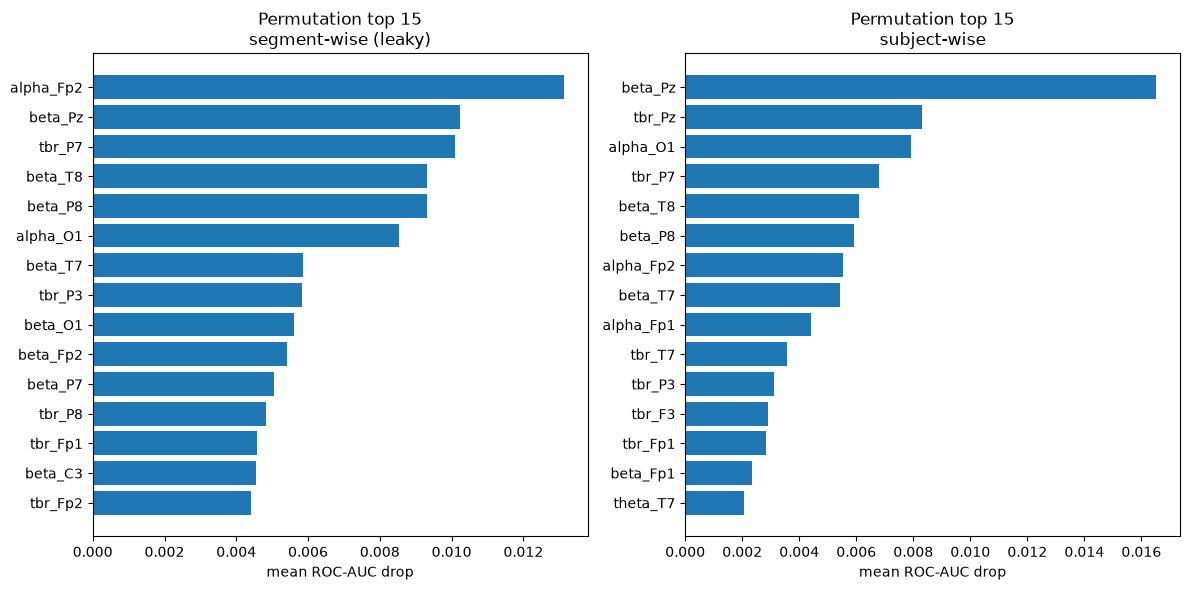

In [6]:
# --- Permutation importance: a second explanation method, out-of-fold ---
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

def perm_importance_oof(cv):
    """Out-of-fold permutation importance (mean ROC-AUC drop), averaged over folds."""
    total = np.zeros(A.shape[1]); n = 0
    for train, test in cv.split(A, label, groups=subject):
        m = RandomForestClassifier(n_estimators=150, n_jobs=-1, random_state=0).fit(A[train], label[train])
        r = permutation_importance(m, A[test], label[test], scoring="roc_auc",
                                   n_repeats=5, random_state=0, n_jobs=1)
        total += r.importances_mean; n += 1
    return pd.Series(total / n, index=names)

perm_segwise = perm_importance_oof(StratifiedKFold(5, shuffle=True, random_state=0))        # segments shuffled
perm_subwise = perm_importance_oof(StratifiedGroupKFold(5, shuffle=True, random_state=0))   # subject-wise

def top10_overlap(a, b):
    return len(set(a.sort_values(ascending=False).head(10).index) &
               set(b.sort_values(ascending=False).head(10).index))

# how much does the split change each explanation (segment-wise vs subject-wise)?
print("agreement between the two splits (segment-wise vs subject-wise):")
print(f"  SHAP        Spearman {spearmanr(imp['segwise'], imp['subwise']).correlation:+.3f}   top-10 overlap {top10_overlap(imp['segwise'], imp['subwise'])}/10")
print(f"  permutation Spearman {spearmanr(perm_segwise, perm_subwise).correlation:+.3f}   top-10 overlap {top10_overlap(perm_segwise, perm_subwise)}/10")

print("\ntotal AUC drop (sum of per-feature permutation importance):")
print(f"  segment-wise split : {perm_segwise.sum():.3f}")
print(f"  subject-wise split : {perm_subwise.sum():.3f}")

# bar plot: top 15 permutation features for each split, side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, ser, title in zip(axes, [perm_segwise, perm_subwise],
                          ["segment-wise (leaky)", "subject-wise"]):
    top = ser.sort_values(ascending=False).head(15)[::-1]
    ax.barh(top.index, top.values)
    ax.set_title(f"Permutation top 15\n{title}")
    ax.set_xlabel("mean ROC-AUC drop")
plt.tight_layout(); plt.show()